# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---
## 🧩Paso 2: Identificación de problemas de calidad de datos
### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print((users.isna().mean())*100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print((usage.isna().mean())*100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).

**Hint:**
- Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
- Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
- Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  

- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

En el dataset users, dos columnas presentan valores nulos: city con 469 valores faltantes (11.7% del total) y churn_date con 3,534 valores faltantes (88.4% del total). En el dataset usage, también hay dos columnas con nulos: date con 50 valores faltantes (0.1%), duration con 22,076 valores faltantes (55.2%) y length con 17,896 valores faltantes (44.8%). El dataset plans no presenta ningún valor nulo en sus 2 registros ya que solo representa dos filas con información prioritaria.

- **city** (11.7% nulos): se imputará con una categoría tipo "Desconocido", ya que eliminar 469 filas implicaría perder información valiosa de otras columnas (edad, plan, uso) de esos mismos clientes, y el porcentaje no es lo suficientemente alto como para ignorarlo.
- **churn_date** (88.4% nulos): es un porcentaje alto en nuestro caso se ignora (no se imputa ni se elimina), porque el nulo no representa un dato faltante sino información válida en la cual el cliente sigue activo y no se ha dado de baja.
- **date (0.1% nulos)**: se eliminarán las 50 filas afectadas con dropna(subset=["date"]), ya que sin fecha el registro no se puede ubicar en el tiempo, y al ser una proporción tan baja no afecta significativamente el tamaño del dataset.
- **duration y length** (55.2% y 44.8% nulos respectivamente): se ignoran, porque no son datos faltantes por error, sino un resultado esperado de la estructura de los datos (cada fila es una llamada o un mensaje, nunca ambos a la vez.




### 2.2 Detección de valores inválidos y sentinels
🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.


In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` es un identificador único de cliente y no aporta información analítica relevante como estadística descriptiva (su media, desviación estándar, etc. no tienen interpretación de negocio); se distribuye de forma uniforme entre 10000 y 13999, sin valores atípicos.
- La columna `age` presenta un valor mínimo de -999, lo cual es falso nadie tiene -999 años y no representa una edad real lo que traduciría en un sentinels. Este valor distorsiona las medidas estadísticas: infla la desviación estándar (123.23, un número muy alto para edades) y reduce el promedio (33.74) muy por debajo de la mediana (47), lo que indica que el sentinel está sesgando la tendencia central hacia abajo. Se recomienda reemplazarlo por NaN antes de continuar con el análisis.

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas **id** y **user_id** son identificadores de los usuarios y de su registro único como se menciono anteriormente no aportan información analítica relevante como estadística descriptiva, ya que su media, desviación estándar y percentiles no tienen interpretación de negocio. id va de 1 a 40000 de forma consecutiva (un registro por fila), y user_id se distribuye entre 10000 y 13999, coincidiendo con el rango de clientes visto en users.
  
- Las columnas **duration** EL tiempo que demora un usuario en una llamada probablemente en minutos tiene un mínimo de 0, un promedio de 5.20, una mediana de 3.5 y un máximo de 120. No se observan valores negativos ni sentinels evidentes. El promedio (5.20) está por encima de la mediana (3.5), lo que sugiere una distribución sesgada hacia la derecha: hay algunas llamadas de mayor duración que "jalan" el promedio hacia arriba, mientras que la mayoría de las llamadas son más cortas. El máximo de 120 no parece un error evidente. Para la columna **length** representa la longitud de los mensajes de texto, probablemente en caracteres tiene un mínimo de 0, un promedio de 52.13, una mediana de 50 y un máximo de 1490. El promedio y la mediana están bastante cercanos entre sí, lo que sugiere que la mayoría de los mensajes tienen una longitud típica y consistente. Sin embargo, el máximo de 1490 se ve considerablemente alejado del percentil 75% (64), lo que indica la posible presencia de outliers.

In [14]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f'Valores únicos - {col}')
    print(users[col].value_counts(dropna=False))
    print()




Valores únicos - city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos - plan
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` de acuerdo a la información obtenida Bogotá es la ciudad con mayor número de usuarios. Esta columna presenta varios problemas de calidad: 469 valores nulos (NaN) y 96 registros con el valor "?", un sentinel de texto que representa un dato faltante disfrazado de valor válido. Además, se observan abreviaciones inconsistentes (GDL para Guadalajara, MTY para Monterrey, CDMX para Ciudad de Mexico) mezcladas con nombres completos (Bogotá, Medellín), lo que indica que esta columna necesitará limpieza y estandarización antes de usarse en cualquier segmentación por ciudad. 
- La columna `plan` nos muestra sus dos categorías válidas "Basico" y "Premium" sin valores inconsistentes.

In [15]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)


text    22092
call    17908
Name: type, dtype: int64

- La columna `type` presenta únicamente dos categorías válidas: text (22,092 registros) y call (17,908 registros). No se detectan valores inconsistentes ni sentinels.




---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  



## 2.3 Revisión y estandarización de fechas
**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
print(users['reg_date'].dtype)
print(users['reg_date'].isna().sum())

datetime64[ns]
0


In [17]:


# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
print(usage['date'].dtype)
print(usage['date'].isna().sum())


datetime64[ns]
50


In [18]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


In [19]:
print(users[users['reg_date'].dt.year == 2026])

      user_id first_name last_name  age      city   reg_date     plan  \
40      10040        Ana    Garcia   59  Medellín 2026-05-10   Basico   
56      10056       Luis    Garcia   29      CDMX 2026-05-10   Basico   
60      10060     Carlos    Torres   45      CDMX 2026-05-10   Basico   
70      10070    Mariana     Gomez   50      CDMX 2026-05-10  Premium   
248     10248      Sofia    Garcia   20  Medellín 2026-05-10  Premium   
320     10320      Sofia    Garcia   74       GDL 2026-05-10  Premium   
326     10326    Mariana    Torres   51  Medellín 2026-05-10  Premium   
505     10505       Luis    Garcia   75      CDMX 2026-05-10   Basico   
527     10527     Carlos    Torres   71       MTY 2026-05-10   Basico   
646     10646       Luis   Ramirez   50      CDMX 2026-05-10  Premium   
885     10885        Ana    Torres   73    Bogotá 2026-05-10   Basico   
914     10914    Mariana    Garcia   25       GDL 2026-05-10   Basico   
948     10948      Sofia    Torres   30       MTY 2

En `reg_date`, en esta columna se observan registros de 2022 (1,314), 2023 (1,316) y 2024 (1,330), distribuidos de forma muy pareja, no se observan registros en 2025 pero si 40 registros en 2026. Al revisarlos, los 40 tienen exactamente la misma fecha (2026-05-10), lo que no es un comportamiento normal de registros reales. Además, estos clientes tienen actividad en usage durante 2024, algo inconsistente parece un error de digitación.

In [20]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


En `date`, se observan que todos los registros de uso son del año 2024: 39,950 en total, que son los 40,000 originales menos los 50 que encontramos con fecha nula. No hay años raros ni fechas fuera de rango.
¿Por qué aparece 2024.0 con decimal? Porque .dt.year devuelve números decimales (float) cuando la columna tiene NaT. Es normal y no es un error. Se resolvería eliminando esos 50 nulos. Basaremos el análisis en estas fechas.




✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**users["reg_date"]**: se encontraron 40 registros con año 2026, todos con la misma fecha exacta (2026-05-10), y ningún registro en 2025 — un salto brusco poco natural para fechas de registro reales. Además, estos mismos clientes tienen actividad registrada en usage durante 2024, lo cual es imposible si su registro fue en 2026 (no pueden haber usado el servicio dos años antes de darse de alta). Esto confirma que 2026-05-10 es una fecha placeholder o un error de captura, no una fecha real. Acción: convertir esas 40 fechas a NaT (tratarlas como ausentes), conservando el resto de la información del cliente, ya que solo el dato de fecha está dañado.

**usage["date"]**: todos los registros válidos corresponden únicamente a 2024 (enero a junio), sin años imposibles ni fechas fuera de ese rango. No se detecta ningún problema adicional en esta columna más allá de los 50 nulos ya identificados y que se eliminarán.

Vale la pena mencionar que este hallazgo de la la inconsistencia correspondiente a la fecha de 2026-05-10 se detectó cruzando información entre users y usage solo así se vuelve evidente al comparar la fecha de registro contra la fecha real de actividad. Es un buen ejemplo de por qué revisar cada dataset por separado no es suficiente; a veces los errores solo se ven al relacionar las tablas.


---
## 🧩Paso 3: Limpieza básica de datos
### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.


In [21]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age']= users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()



count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city

users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].isna().sum()


565

In [23]:
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [24]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = np.where(users['reg_date'].dt.year == 2026, pd.NaT, users['reg_date'])
users['reg_date'] = pd.to_datetime(users['reg_date'])

# Verificar cambios
users['reg_date'].isna().sum()

40

In [25]:
# Ver el nuevo formato de las 40 filas que tenían año 2026
users[users['reg_date'].isna()]

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
40,10040,Ana,Garcia,59.0,Medellín,NaT,Basico,NaN
56,10056,Luis,Garcia,29.0,CDMX,NaT,Basico,"1,72187E+18"
60,10060,Carlos,Torres,45.0,CDMX,NaT,Basico,NaN
70,10070,Mariana,Gomez,50.0,CDMX,NaT,Premium,NaN
248,10248,Sofia,Garcia,20.0,Medellín,NaT,Premium,"1,72506E+18"
320,10320,Sofia,Garcia,74.0,GDL,NaT,Premium,NaN
326,10326,Mariana,Torres,51.0,Medellín,NaT,Premium,NaN
505,10505,Luis,Garcia,75.0,CDMX,NaT,Basico,NaN
527,10527,Carlos,Torres,71.0,MTY,NaT,Basico,NaN
646,10646,Luis,Ramirez,50.0,CDMX,NaT,Premium,NaN


In [48]:
# Estandarizar nombres de ciudad
users['city'] = users['city'].replace({
    'GDL': 'Guadalajara',
    'MTY': 'Monterrey',
    'CDMX': 'Ciudad de México'
})

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá              808
Ciudad de México    730
Medellín            616
NaN                 565
Guadalajara         450
Cali                424
Monterrey           407
Name: city, dtype: int64

Se estandarizaron los nombres de ciudad reemplazando las abreviaciones GDL, MTY y CDMX por Guadalajara, Monterrey y Ciudad de México, para que la columna use un formato consistente.Los conteos no cambian, solo los nombres. Los 565 nulos siguen ahí (469 originales más los 96 de "?").

## 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  

  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.



In [49]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].count()


type
call    17908
text       16
Name: duration, dtype: int64

In [50]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].count()

type
call       12
text    22092
Name: length, dtype: int64

In [51]:
usage.groupby('type').size()

type
call    17908
text    22092
dtype: int64

In [52]:
# Filas de tipo text que tienen valor en duration
usage[(usage['type'] == 'text') & (usage['duration'].notna())]

,id,user_id,type,date,duration,length
1414,1415,10399,text,2024-01-07 09:33:51.260781519,120.0,65.0
1824,1825,12936,text,2024-01-09 06:05:28.868221705,120.0,40.0
1932,1933,10189,text,2024-01-09 17:49:13.603840096,120.0,69.0
2972,2973,10085,text,2024-01-14 10:46:02.169054226,120.0,68.0
11456,11457,13325,text,2024-02-21 20:09:09.733743343,120.0,23.0
16702,16703,10484,text,2024-03-16 13:52:57.169429235,120.0,48.0
22814,22815,12711,text,2024-04-13 05:39:44.429610740,120.0,70.0
23052,23053,13850,text,2024-04-14 07:30:35.235880896,120.0,24.0
23451,23452,13265,text,2024-04-16 02:50:32.175804394,120.0,53.0
26561,26562,13920,text,2024-04-30 04:35:48.173704342,120.0,89.0


In [53]:
# Filas de tipo call que tienen valor en length
usage[(usage['type'] == 'call') & (usage['length'].notna())]

,id,user_id,type,date,duration,length
2070,2071,13139,call,2024-01-10 08:48:27.432685817,1.68,1490.0
5272,5273,11750,call,2024-01-24 20:33:12.649816245,3.78,1490.0
10614,10615,13855,call,2024-02-18 00:42:33.183829595,0.53,1490.0
12692,12693,12263,call,2024-02-27 10:23:08.374709367,1.80,1490.0
16910,16911,12099,call,2024-03-17 12:28:18.882472061,3.29,1490.0
20727,20728,10599,call,2024-04-03 19:00:30.510762768,0.40,1490.0
20778,20779,11401,call,2024-04-04 00:32:49.969249231,1.01,1490.0
25444,25445,10781,call,2024-04-25 03:17:14.935873396,3.57,1490.0
26057,26058,11018,call,2024-04-27 21:51:39.407485186,0.63,1490.0
26506,26507,12400,call,2024-04-29 22:37:24.836120902,1.12,1490.0


Diagnostico de nulos en `duration` y `length`

Los nulos de duration y length son MAR ya que dependen de la columna type.  **duration** solo aplica a call y **length** solo aplica a text, así que su ausencia en el otro tipo es estructural, no un error de captura. Por lo tanto se decide dejar como nulos, sin imputar ni eliminar, porque imputarlos crearía duraciones de llamada para mensajes (y longitudes de mensaje para llamadas) que no existen. Tener en cuenta que cualquier valor (media, mediana) inventaría duraciones para mensajes y longitudes para llamadas, y distorsionaría las estadísticas. Tampoco se eliminan filas, porque cada fila tiene el dato que sí le corresponde.

Se identificaron 28 registros con un campo que no corresponde a su tipo: 16 mensajes con duration = 120 y 12 llamadas con length = 1490. Al ser valores únicos y repetidos, se interpretan como sentinels o errores de registro. Parecen errores de registro y se revisarán en el análisis de outliers.

---
## 🧩Paso 4: Summary statistics de uso por usuario

### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.


In [54]:
# Renombrar columnas
usage_agg = usage.groupby('user_id').agg(
    cant_mensajes=('length', 'count'),
    cant_llamadas=('duration', 'count'),
    cant_minutos_llamada=('duration', 'sum')
)

# observar resultado
usage_agg.head(3)

,cant_mensajes,cant_llamadas,cant_minutos_llamada
user_id,,,
10000,7,3,23.70
10001,5,10,33.18
10002,5,2,10.74


In [55]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, left_on='user_id', right_index=True, how='left')
# observar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,Ciudad de México,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,Guadalajara,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [56]:
# Resumen estadístico de las columnas numéricas
columnas_num = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_num].describe()



,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.527382,4.482121,23.317054
std,17.690408,2.358383,2.145092,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


**Analisis de las columnas númericas**

**age**: va de 18 a 79 años, con media 48.12 y mediana 47. Están muy cerca, así que la distribución es bastante simétrica y el -999 ya no distorsiona nada.

**cant_mensajes y cant_llamadas**: medias de 5.5 y 4.5, con medianas casi iguales (5 y 4). El uso por cliente es bajo y homogéneo, sin sesgo fuerte

**cant_minutos_llamada**: aquí sí hay señal. La media (23.32) es mayor que la mediana (19.78), y el máximo (155.69) está muy por encima del percentil 75 (31.42). Hay pocos usuarios con minutos muy altos que jalan el promedio, candidatos a outliers para el Paso 5.

**count** = 3999 en las métricas de uso: es el cliente sin registros en usage, que quedó como nulo tras el merge.

In [34]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

**plan**: 64.88% Básico (2,595 clientes) y 35.12% Premium (1,405). Casi dos de cada tres clientes tienen el plan más barato.

---
## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers
### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas


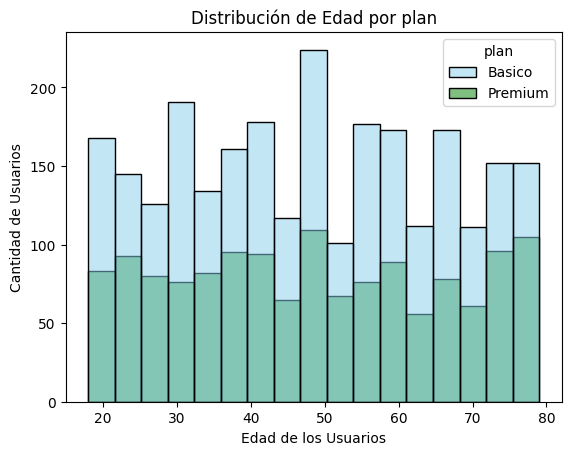

In [57]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'])
plt.title( 'Distribución de Edad por plan')
plt.xlabel('Edad de los Usuarios')
plt.ylabel ('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Distribución aproximadamente uniforme y simétrica, entre 18 y 79 años (media 48, mediana 47), sin concentración clara. Los dos planes tienen perfiles de edad muy parecidos; Básico se ve más alto solo porque tiene más clientes. No existe un patrón por plan.

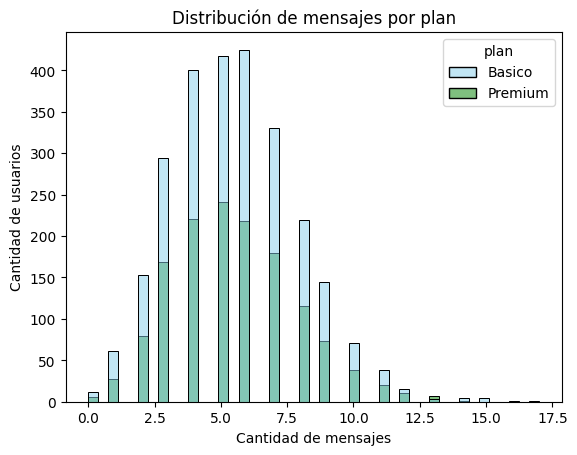

In [36]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución ligeramente sesgada a la derecha: la mayoría de los usuarios envía entre 3 y 8 mensajes y pocos superan los 10. La media y la mediana son casi iguales en ambos planes (5.5 y 5), así que Básico y Premium se comportan igual. Básico se ve más alto solo porque tiene más clientes. No existe un patrón por plan.

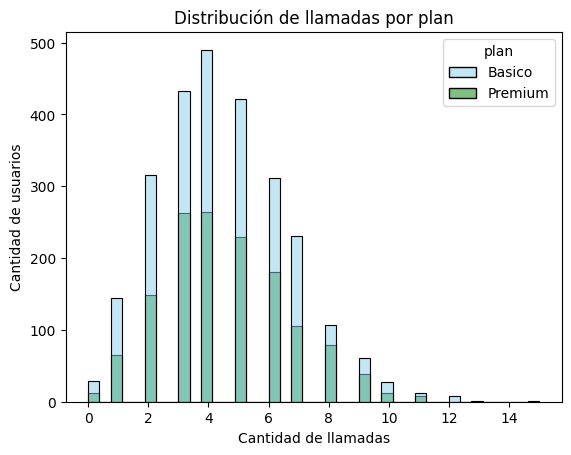

In [37]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- Distribución ligeramente sesgada a la derecha: la mayoría de los usuarios hace entre 2 y 6 llamadas (media 4.5, mediana 4) y pocos superan las 10. Básico y Premium se comportan igual, así que no existe un patrón por plan. Las barras de Básico son más altas porque tiene más clientes.

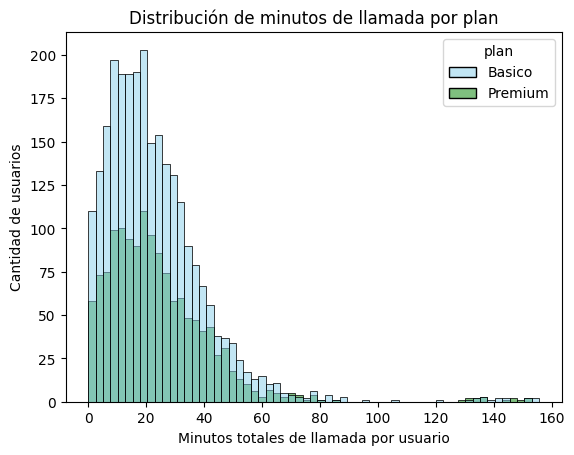

In [38]:
# Histograma para visualizar la cant_minutos_llamada

sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Minutos totales de llamada por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución claramente sesgada a la derecha: la mayoría de los usuarios acumula entre 0 y 50 minutos, pero existe una cola larga con usuarios que superan los 120. La media (23.3) es mayor que la mediana (19.8), lo que confirma el sesgo. Premium tiene una media ligeramente mayor (24.1 vs 22.9), una diferencia pequeña que no muestra un patrón claro. Los usuarios de la cola derecha son candidatos a outliers.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.


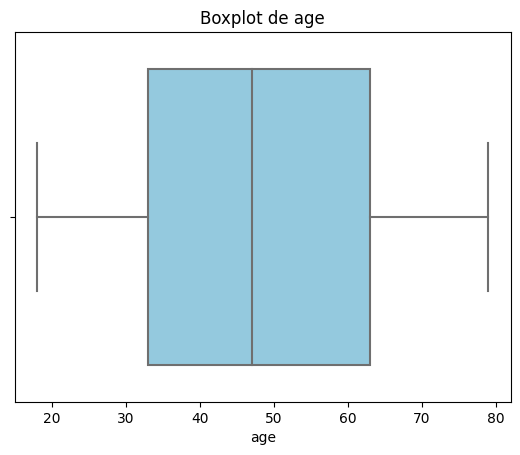

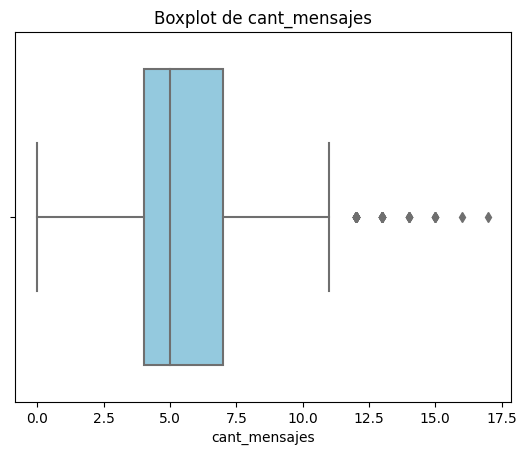

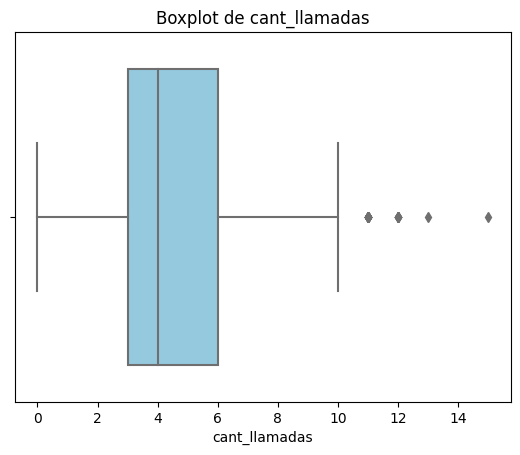

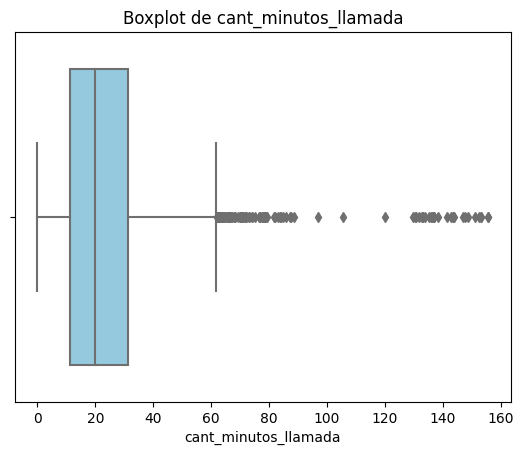

In [39]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot de {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: No presenta outliers. La caja y los bigotes cubren todo el rango (18 a 79 años) y el boxplot no muestra puntos fuera de ellos
- cant_mensajes: Presenta outliers solo hacia arriba con una mediana de 5 años. Parecen usuarios con mucha actividad y no errores de registro
- cant_llamadas: Presenta outliers solo hacia arriba. El límite superior es 10.5 llamadas, y presenta una mediana de 4.
- cant_minutos_llamada: es la variable con más outliers, también solo hacia arriba. El límite superior es 61.86 minutos, con un grupo separado entre 130 y 155 minutos. Se conservan por ser consumo posiblemente real y de alto valor comercial. Se marca para revisión que 16 de los 29 usuarios con más de 120 minutos tienen una fila de tipo text con duration = 120 (las anomalías del punto 3.2), que infla su total.

In [40]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f'{col}: límite superior = {limite_superior:.2f}, outliers = {n_outliers}')


cant_mensajes: límite superior = 11.50, outliers = 46
cant_llamadas: límite superior = 10.50, outliers = 30
cant_minutos_llamada: límite superior = 61.86, outliers = 109


In [41]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.527382,4.482121,23.317054
std,2.358383,2.145092,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Se mantienen los outliers. El límite superior es 11.5 mensajes y el máximo es 17, solo 1.5 veces por encima del límite. Afectan a 46 usuarios. Son cantidades creibles para clientes muy activos y no parecen errores de captura. Eliminarlos haría perder justo a los usuarios de mayor consumo.
- cant_llamadas: mantener o no outliers, porqué? Se mantienen los outliers. El límite superior es 10.5 llamadas y el máximo es 15, solo 1.4 veces por encima. Afectan a 30 usuarios (0.75%). Es un uso alto pero realista, y esos clientes son relevantes para el análisis comercial.
- cant_minutos_llamada: mantener o no outliers, porqué? se mantienen los outliers, con una salvedad. El límite superior es 61.86 minutos y el máximo es 155.69, unas 2.5 veces por encima de ese valor. Afectan a 109 usuarios (2.73%), la mayor proporción de las tres variables. Un consumo de 155 minutos es posible y corresponde a los clientes de mayor uso. Se deja anotado que 16 de los usuarios con más de 120 minutos tienen su total inflado por las filas text con duration = 120 del punto 3.2, por lo que esos casos conviene revisarlos.

---
## 🧩Paso 6: Segmentación de Clientes
### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:

  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5

  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [58]:
# Crear columna grupo_uso

cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
grupos = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, grupos, default='Alto uso')

user_profile[['cant_llamadas', 'cant_mensajes', 'grupo_uso']].head()


,cant_llamadas,cant_mensajes,grupo_uso
0,3.0,7.0,Uso medio
1,10.0,5.0,Alto uso
2,2.0,5.0,Uso medio
3,3.0,11.0,Alto uso
4,3.0,4.0,Bajo uso


In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso



### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
# Crear columna grupo_edad
condiciones_edad = [user_profile['age'] < 30, user_profile['age'] < 60]
grupos_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, grupos_edad, default='Adulto Mayor')

In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor



### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.



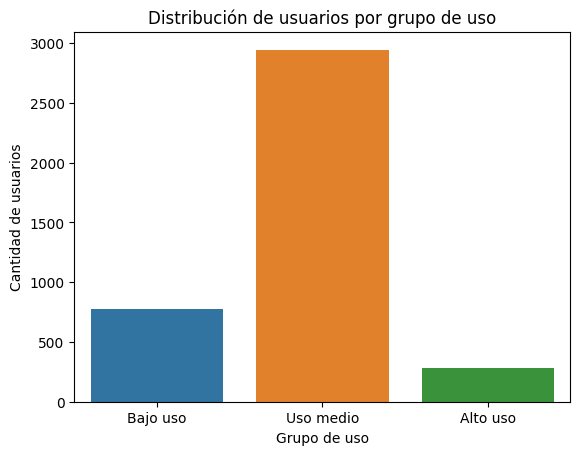

In [46]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'])
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()


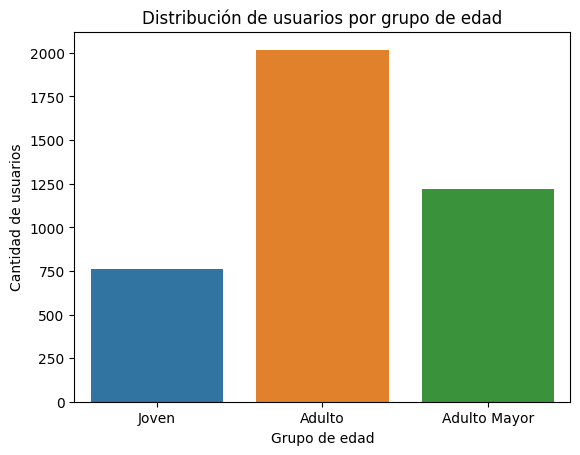

In [47]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**



### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- city fue la columna más afectada: 14.1% eran nulos o sentinels (469 nulos y 96 "?") y abreviaciones mezcladas con nombres completos, y sin estandarizar habría fragmentado cualquier análisis por ciudad. Las demás son pocas filas había 55 edades -999 (1.4%), 40 fechas de registro imposibles (1.0%), 50 registros de uso sin fecha (0.1%) y 28 filas con un campo del tipo contrario (0.07%). El -999 hundía la edad media de 48 a 34 años se corrigió o se marcó como nulo. pero distorsionaban estadísticasy la fecha de 2026 falseaba la antigüedad de 40 clientes.

Los nulos de duration (55.2%) y length (44.8%) no son un problema: dependen de type, porque una llamada no tiene longitud de mensaje y un mensaje no tiene duración. Se verificó que son MAR y se dejaron como nulos.

🔍 **Segmentos por Edad**

- Identificamos como se comportan los segmentos por edad 50.5% Adultos (30 a 59 años), 30.6% Adultos Mayores (60 o más) y 19.0% Jóvenes (menos de 30). Los Adultos son el segmento más grande de la base.
- Los tres grupos se comportan casi igual: ~5.5 mensajes y ~4.5 llamadas por usuario, con 23 a 24 minutos de llamada en total.
- La distribución por nivel de uso también es parecida: entre 72% y 74% de cada grupo es de uso medio.

  Por lo tanto, la edad no cambia el comportamiento de uso: los tres grupos consumen casi lo mismo.

📊 **Segmentos por Nivel de Uso**

- Identificamos tres niveles de uso: 73.6% uso medio, 19.4% bajo y 7.0% alto. La gran mayoría de los clientes tiene un consumo moderado.
- Se diferencian con claridad en su consumo. Un usuario de alto uso envía 9.6 mensajes, hace 6 llamadas y acumula 30 minutos. Uno de bajo uso envía 3.1 mensajes, hace 2.8 llamadas y acumula 15 minutos. El de uso medio queda entre ambos (5.8 mensajes, 4.8 llamadas y 25 minutos).
El segmento de alto uso es pequeño pero relevante: tiene la mayor tasa de baja, 14.3%, frente a 11.5% en los otros dos grupos.
El plan contratado tampoco separa los niveles de uso: la proporción Básico/Premium es casi igual en los tres grupos (entre 64% y 66% Básico).


➡️ Esto sugiere que el nivel de uso depende de hábitos individuales y no de la edad ni del plan, por lo que los esfuerzos comerciales deben dirigirse por comportamiento y no por perfil demográfico.

🔍 **Segmentos por Edad****Segmentos más valiosos para connectel** 

- Premium es 35% de la base y aporta ~53% del ingreso fijo. Alto uso (7%) consume más y tiene la mayor tasa de baja (14.3% frente a ~11.5%), así que perderlo cuesta más. Los Adultos son la mitad de la base. La baja global es de 11.65%.

➡️ **Outliers**

Los outliers encontrados se evidencian solo hacia arriba: 46 en mensajes, 30 en llamadas y 109 en minutos (máximo 155.7). Se mantuvieron por ser consumo plausible. Ni el usuario más extremo se acerca a los límites de su plan (~26 minutos al mes frente a 100 en Básico), y no hay evidencia de fraude masivo.

💡 **Recomendaciones**

- Justificar Premium con datos de GB, porque en llamadas y mensajes es igual a Básico. Revisar la propuesta de valor de Premium. Si su diferencia está en los GB (20 frente a 5), hay que medir ese uso y comunicarlo, porque esos datos no están en este análisis. Sin esa justificación, Premium es vulnerable a la migración hacia el plan más barato.
- Evaluar un plan de entrada más económico. Con menos minutos y mensajes que Básico. El cliente más activo usa una fracción de lo incluido, así que ese plan cubriría casi toda la base. Es una hipótesis que debe validarse con precios y datos de GB.
- Programa de retención para Alto uso. Ofertas de fidelización o beneficios proactivos, dado que tienen la mayor tasa de baja.
- Campañas para Adultos de 30 a 59 años. Son la mitad de la base, con mensajes de actualización a Premium.
- Validar la captura de datos en origen. Tener información de solo llamadas y mensajes de enero a junio de 2024 no es suficiente teniendo en cuenta que el mercado se basa en el consumo de datos y hace exclusion no tenemosel consumo de datos en GB.

---
## 🧩Paso 8 Cargar tu notebook y README a GitHub
🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`